# Tarea 8.2 

Encuentre la separación óptima entre puntos para el ejemplo con ruido hecho en clase.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)   # semilla para reproducibilidad

## 1. Funciones de la clase

Derivada de datos equiespaciados: fórmula centrada de tres puntos en el interior y fórmula lateral de tres puntos en los extremos (con $-h$ en el borde derecho).

In [2]:
def deriv3_datos(fxm, fxp, h):
    # f'(x) ≈ [f(x+h) - f(x-h)] / (2h)
    return (fxp - fxm) / (2*h)

def deriv3_borde_datos(fx0, fx1, fx2, h):
    # f'(x) ≈ [-3 f(x) + 4 f(x+h) - f(x+2h)] / (2h)
    return (-3*fx0 + 4*fx1 - fx2) / (2*h)

def deriv_datos(fx, h):
    n = len(fx)
    deriv = np.zeros(n)
    for i in range(1, n-1):
        deriv[i] = deriv3_datos(fx[i-1], fx[i+1], h)
    deriv[0] = deriv3_borde_datos(fx[0], fx[1], fx[2], h)
    deriv[-1] = deriv3_borde_datos(fx[-1], fx[-2], fx[-3], -h)
    return deriv

## 2. El ejemplo de clase

20 puntos en $[0,4]$ y ruido con $\Delta=0.001$.

**Nota:** en clase se usó h = 4/num. Aquí se usa la separación real h = x[1] - x[0] para no introducir un error sistemático extra.

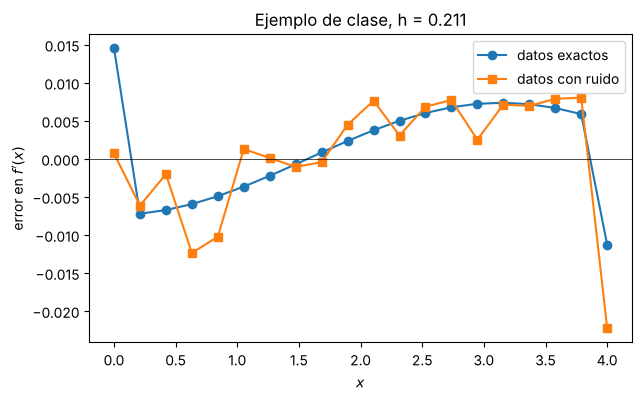

In [3]:
Delta = 0.001
num = 20
x = np.linspace(0, 4, num)
h = x[1] - x[0]

datos_e = np.sin(x)
datos_r = np.sin(x) + rng.normal(0, Delta, num)

plt.figure(figsize=(7, 4))
plt.plot(x, deriv_datos(datos_e, h) - np.cos(x), 'o-', label='datos exactos')
plt.plot(x, deriv_datos(datos_r, h) - np.cos(x), 's-', label='datos con ruido')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel('$x$'); plt.ylabel("error en $f'(x)$")
plt.title(f'Ejemplo de clase, h = {h:.3f}')
plt.legend(); plt.show()

## 3. Separación óptima: análisis teórico

Si cada dato tiene un error de a lo más $\Delta$, $\tilde f(x_i) = f(x_i) + \epsilon_i$ con $|\epsilon_i|\le\Delta$, la cota de clase para la fórmula centrada es

$$\left|f'(x_o) - \frac{\tilde f(x_o+h) - \tilde f(x_o-h)}{2h}\right| \le E(h) = \frac{\Delta}{h} + \frac{h^2}{6}M,
\qquad M = \max|f'''(x)|.$$

El primer término (ruido) crece al disminuir $h$; el segundo (truncamiento) crece al aumentar $h$. El mínimo está donde $E'(h)=0$:

$$ E'(h) = -\frac{\Delta}{h^2} + \frac{h}{3}M = 0
\quad\Longrightarrow\quad{h_{\rm opt} = \left(\frac{3\Delta}{M}\right)^{1/3}},
\qquad
E(h_{\rm opt}) = \frac{3\Delta}{2\,h_{\rm opt}}.$$

Para $f(x)=\sin x$, $f'''(x) = -\cos x$, así que en $[0,4]$ se tiene $M = 1$ (alcanzado en $x=0$). Con $\Delta = 10^{-3}$:

$$ h_{\rm opt} = (3\times10^{-3})^{1/3} \approx 0.144 .$$



In [4]:
M = 1.0   # max |f'''(x)| = max |cos x| en [0, 4]
h_opt = (3*Delta/M)**(1/3)
E_opt = Delta/h_opt + h_opt**2*M/6
N_opt = 4/h_opt + 1

print(f"h_opt (teórico)            = {h_opt:.4f}")
print(f"cota de error en h_opt     = {E_opt:.2e}")
print(f"número de puntos en [0,4]  ≈ {N_opt:.1f}")
print(f"cota de error con h={h:.3f} (clase) = {Delta/h + h**2*M/6:.2e}")

h_opt (teórico)            = 0.1442
cota de error en h_opt     = 1.04e-02
número de puntos en [0,4]  ≈ 28.7
cota de error con h=0.211 (clase) = 1.21e-02


## 4. Verificación numérica

Ahora barremos el número de puntos $N$ (y por tanto $h = 4/(N-1)$). Para cada $h$ genero 500 realizaciones del ruido y medimos, en los puntos interiores donde la fórmula centrada aplica:

- el **error máximo** sobre $x$ (comparable con la cota $E(h)$),
- el **error cuadrático medio** (RMS) sobre $x$.



In [5]:
Ns = np.unique(np.round(np.logspace(np.log10(5), np.log10(2000), 120)).astype(int))
n_real = 500

hs, err_max, err_rms = [], [], []
for N in Ns:
    x = np.linspace(0, 4, N)
    hN = x[1] - x[0]
    exacta = np.cos(x)[1:-1]
    emax, erms = [], []
    for _ in range(n_real):
        fx = np.sin(x) + rng.normal(0, Delta, N)
        d = (fx[2:] - fx[:-2]) / (2*hN)          # = deriv3_datos, vectorizado
        e = np.abs(d - exacta)
        emax.append(e.max())
        erms.append(np.sqrt(np.mean(e**2)))
    hs.append(hN); err_max.append(np.mean(emax)); err_rms.append(np.mean(erms))

hs, err_max, err_rms = map(np.array, (hs, err_max, err_rms))

h_num_max = hs[np.argmin(err_max)]
h_num_rms = hs[np.argmin(err_rms)]
print(f"h óptimo numérico (error máximo) = {h_num_max:.4f}")
print(f"h óptimo numérico (error RMS)    = {h_num_rms:.4f}")
print(f"h óptimo teórico                 = {h_opt:.4f}")

h óptimo numérico (error máximo) = 0.1818
h óptimo numérico (error RMS)    = 0.1600
h óptimo teórico                 = 0.1442


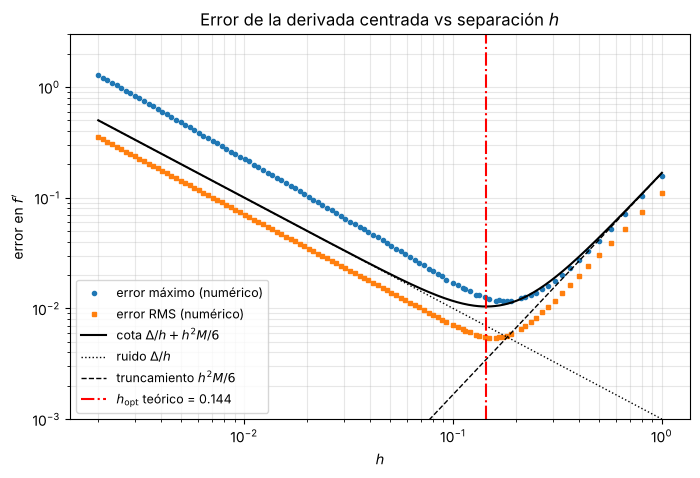

In [6]:
hh = np.logspace(np.log10(hs.min()), np.log10(hs.max()), 400)

plt.figure(figsize=(8, 5))
plt.loglog(hs, err_max, 'o', ms=3, label='error máximo (numérico)')
plt.loglog(hs, err_rms, 's', ms=3, label='error RMS (numérico)')
plt.loglog(hh, Delta/hh + hh**2*M/6, 'k-', label=r'cota $\Delta/h + h^2M/6$')
plt.loglog(hh, Delta/hh, 'k:', lw=1, label=r'ruido $\Delta/h$')
plt.loglog(hh, hh**2*M/6, 'k--', lw=1, label=r'truncamiento $h^2M/6$')
plt.axvline(h_opt, color='r', ls='-.', label=rf'$h_{{\rm opt}}$ teórico = {h_opt:.3f}')
plt.ylim(1e-3, 3)
plt.xlabel('$h$'); plt.ylabel("error en $f'$")
plt.title('Error de la derivada centrada vs separación $h$')
plt.legend(fontsize=9); plt.grid(True, which='both', alpha=0.3)
plt.show()

Las curvas numéricas tienen la forma de "V" esperada: para $h$ pequeño domina el ruido (pendiente $-1$) y para $h$ grande el truncamiento (pendiente $+2$). El mínimo numérico ($h\approx0.16$–$0.18$) cae cerca del $h_{\rm opt}\approx0.14$ teórico; la curva de error es muy plana alrededor del mínimo, así que cualquier $h$ en ese rango da prácticamente el mismo error. Las pequeñas diferencias se entienden así:

- **Error RMS:** el truncamiento real es $\frac{h^2}{6}|\cos x|$, no $\frac{h^2}{6}M$. Promediado sobre $[0,4]$, $\langle\cos^2x\rangle\approx0.56$, lo que equivale a un $M_{\rm ef}\approx0.75$ y da $(3\Delta/M_{\rm ef})^{1/3}\approx0.16$, justo lo observado.
- **Error máximo:** como el ruido es gaussiano, $\Delta$ es una desviación estándar y no una cota estricta: con muchos puntos aparecen valores de $|\epsilon_i|$ de $3\Delta$ o más. Por eso el error máximo supera la "cota" para $h$ pequeño y su mínimo se desplaza un poco hacia $h$ mayores (menos puntos).



## 5. Conclusión

Para la fórmula de tres puntos aplicada a datos con ruido de amplitud $\Delta$, la separación que minimiza la cota de error es

$$h_{opt} = \left(\frac{3\Delta}{M}\right)^{1/3}.$$

En el ejemplo de clase ($f = \sin x$, $M = 1$, ruido con $\Delta = 0.001$) esto da **$h_{opt} \approx 0.14$**, unos 29 puntos en $[0, 4]$. Los experimentos numéricos ubican el mínimo del error en $h \approx 0.16$–$0.18$ (entre 23 y 26 puntos), donde el error máximo de la derivada es de alrededor de $0.012$. La pequeña diferencia viene de que el ruido es gaussiano y no acotado, y en la práctica casi no importa, porque el mínimo es plano. En resumen, la separación óptima es **$h \approx 0.15$–$0.18$**, es decir, entre 23 y 28 puntos en el intervalo.

## Nota: 7.0

Base: 1/1; funcionamiento: 4/4; comentarios: 1/1; claridad: 1/1.
